# EDA: what is associated with Netflix TV series popularity

Cleaning is in `src/tmdb_tv_shows/clean.py`, the reasons are in `tmdb.ipynb`. This notebook only explores. **Assumed** means not verified.

`netflix` = shows where Netflix is in `networks` **or** the `homepage` is on netflix.com (2,031 shows).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tmdb_tv_shows.clean import build

raw, clean, dedup, dropped = build()
netflix = dedup[dedup.is_netflix].copy()
print(len(dedup), len(netflix))   # 164705 2031

164705 2031


## 1. Data quality

Checks on the 2,031 Netflix shows: missing data, flags and zeros, columns, Netflix coverage, outliers, then a summary.

### Missing data

- `tagline` 80.9% missing. A marketing slogan, **assumed** weak from domain knowledge. Not used.
- `created_by` 45.6% missing. Interesting, but imputing creators is not feasible. No imputation.
- Usable with a missing-value approach: `episode_run_time` 28.6%, `production_companies` 27.4%, `production_countries` 12.3%, `vote_average` 12.1% (no votes).
- `networks` is 2.0% missing, the homepage-only shows with a blank `networks`.
- The table below also lists our added columns, so some rows repeat (`genres` and `genres_list`).

In [2]:
cols = list(netflix.columns)
missing = netflix[cols].isna().agg(["sum", "mean"]).T
missing["mean"] = (missing["mean"] * 100).round(1)
missing.sort_values("mean", ascending=False)

,sum,mean
tagline,1643.0,80.9
created_by,926.0,45.6
created_by_list,926.0,45.6
episode_run_time,580.0,28.6
production_companies_list,556.0,27.4
production_companies,556.0,27.4
production_countries,250.0,12.3
vote_average,246.0,12.1
last_air_date,210.0,10.3
homepage,186.0,9.2


### Flags and zeros

- `dates_reversed` and `votes_inconsistent` are 0 in Netflix.
- 246 shows have 0 votes, so `vote_average` is missing. 548 have 5 or fewer votes.
- `popularity` is 0 for 4 shows, the smallest positive value is 0.6.
- 153 shows have no `first_air_date` and 4 start after 2024-04-04 (157 not launched by date).

In [3]:
print(netflix.dates_reversed.sum(), netflix.votes_inconsistent.sum())               # 0 0
print((netflix.vote_count == 0).sum(), (netflix.vote_count <= 5).sum())            # 246 548
print((netflix.popularity == 0).sum(), netflix.popularity[netflix.popularity > 0].min())   # 4 0.6
print(netflix.first_air_date.isna().sum(), (netflix.first_air_date > "2024-04-04").sum())  # 153 4

0 0
246 548
4 0.6
153 4


### Columns with little information or overlap

- `in_production` repeats `status` exactly.
- `adult` is True for 3 shows, almost constant.
- `type` has 5 values (Scripted, Miniseries, Reality, Documentary, Talk Show), usable. **Assumed** known before launch.
- `original_language` equals the first of `languages` in about 91% of shows, so they overlap.

In [4]:
orig = list(raw.columns)
print(netflix[orig].astype(str).nunique().sort_values().head(8))
print(netflix.adult.value_counts())   # False 2028, True 3
print(netflix.type.value_counts())
print(pd.crosstab(netflix.status, netflix.in_production))
print((netflix.original_language == netflix.languages.str.split(", ").str[0]).mean())

in_production         2
adult                 2
status                5
type                  5
number_of_seasons    13
original_language    34
origin_country       81
episode_run_time     90
dtype: int64
adult
False    2028
True        3
Name: count, dtype: int64
type
Scripted       1165
Miniseries      447
Reality         212
Documentary     185
Talk Show        22
Name: count, dtype: int64
in_production     False  True 
status                        
Canceled            213      0
Ended              1009      0
In Production         0    151
Planned               0     42
Returning Series      0    616
0.913343180699163


### Netflix coverage

- TMDB's guideline says `networks` typically lists only the first network to air a show, so licensed shows (Friends on NBC) list their original network.
- 1,929 shows match by network, 1,718 by netflix.com homepage, 1,616 both. 102 are homepage only: 41 with blank `networks`, 61 with other networks.
- Among the network matches, 181 list other networks too (YouTube, Channel 3 and others).
- `networks` is never changed. The homepage match is its own column.

In [5]:
print(netflix.netflix_network.sum(), netflix.netflix_homepage.sum(),
      (netflix.netflix_network & netflix.netflix_homepage).sum())     # 1929 1718 1616
h = netflix[~netflix.netflix_network & netflix.netflix_homepage]
print(len(h), h.networks.isna().sum(), h.networks.notna().sum())      # 102 41 61
nn = netflix[netflix.netflix_network]
k = nn.networks_list.apply(len)
print((k == 1).sum(), (k > 1).sum())                                  # 1748 181
h[h.networks.notna()][["name", "networks"]].head()

1929 1718 1616
102 41 61
1748 181


,name,networks
27,Friends,NBC
3725,Top Boy,Channel 4
6894,Rabbids Invasion,"France 3, Nicktoons"
12009,Some Assembly Required,YTV
5379,Historia de un clan,Telefe


### Outliers

- Seasons (max 30) and episodes (max 973) are long-running shows, genuine. Power Rangers, Pen Tor (817), Bakugan, Friends.
- `episode_run_time` max 515 (Tunnel, 16 episodes). The largest look like total runtimes, not per episode. **Assumed**, not proven. None above 600.
- Votes and popularity are very skewed but real (Money Heist 17,836 votes, Sex Education popularity 1,009).
- Kept everything. Use log scales or medians in EDA.

In [6]:
num = ["number_of_seasons", "number_of_episodes", "episode_run_time", "vote_count", "popularity"]
print(netflix[num].describe(percentiles=[.5, .9, .99]).round(1).T)
big = netflix.nlargest(5, "episode_run_time")[["name", "number_of_episodes", "episode_run_time"]]
big.assign(per_episode=big.episode_run_time / big.number_of_episodes)

                     count   mean    std  min   50%    90%     99%      max
number_of_seasons   2031.0    1.6    1.5  1.0   1.0    3.0     7.0     30.0
number_of_episodes  2029.0   15.2   34.2  0.0   8.0   32.0    92.4    973.0
episode_run_time    1451.0   41.0   25.4  3.0  41.0   60.0   107.5    515.0
vote_count          2031.0  191.7  891.0  0.0  20.0  313.0  2799.2  17836.0
popularity          2031.0   15.6   40.8  0.0   6.5   31.7   144.1   1009.0


,name,number_of_episodes,episode_run_time,per_episode
41246,Tunnel,16.0,515.0,32.1875
2687,The One,8.0,337.0,42.1250
5184,The Innocent Man,6.0,288.0,48.0000
36408,Sunshine Eyes,10.0,275.0,27.5000
5569,The Pharmacist,4.0,217.0,54.2500


### Data quality summary

- **Complete or nearly:** `id`, `name`, `type`, `status`, `popularity`, `vote_count`, `original_language`, `number_of_seasons`, plus `genres`, `origin_country`, `languages`, `overview` (each under 4% missing).
- **Usable with a missing-value approach:** `episode_run_time`, `production_companies`, `production_countries`, `vote_average`.
- **Weak or not used:** `tagline`, `created_by`, `in_production`, `adult`, links and images.
- **Cautions:** popularity is one noisy snapshot, `vote_average` is unreliable for few votes, some runtimes may be totals, the Netflix label depends on `networks` plus homepage, the snapshot date (2024-04-04) is inferred, 157 shows are not launched by date.

In [7]:
SNAPSHOT = pd.Timestamp("2024-04-04")   # latest last_air_date in the data, assumed capture date

launched = netflix[netflix.first_air_date.notna() & (netflix.first_air_date <= SNAPSHOT)].copy()
print(len(netflix), len(launched))      # expect 2031 1874
launched.status.value_counts()


2031 1874


status
Ended               1009
Returning Series     608
Canceled             212
In Production         44
Planned                1
Name: count, dtype: int64

16.674665421558164 7.3100000000000005


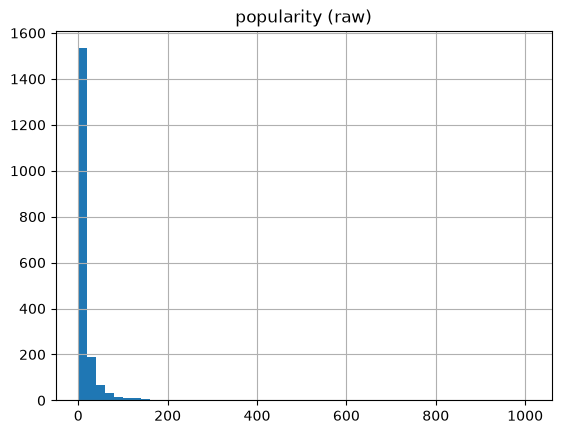

In [8]:
launched.popularity.hist(bins=50)
plt.title("popularity (raw)")
print(launched.popularity.mean(), launched.popularity.median())

2.209027964199965 2.1174594930195036
skew raw: 12.09 | log1p: 0.76


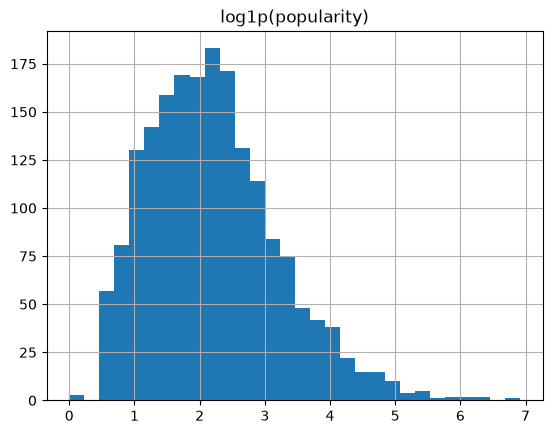

In [9]:
launched["log_pop"] = np.log1p(launched.popularity)

launched.log_pop.hist(bins=30)
plt.title("log1p(popularity)")
print(launched.log_pop.mean(), launched.log_pop.median())
print("skew raw:", round(launched.popularity.skew(), 2), "| log1p:", round(launched.log_pop.skew(), 2))

## 2. Patterns and relationships

Launched Netflix shows only (1,874). Popularity is read as `log_pop = log1p(popularity)`, medians not means.

### Popularity by launch year

- Launch years before 2014 have too few shows each, so they are pooled into one bucket (33 shows). 2024 is a partial year.
- The shaded band is the 95% bootstrap range of the median: how much the median would move with a slightly different set of shows.


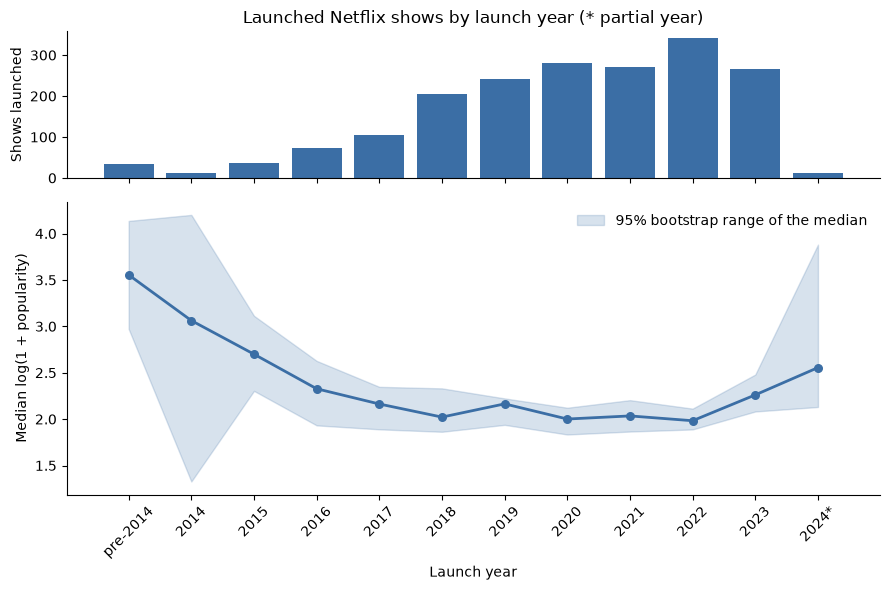

pre-2014: n=33, median=3.55, range 2.97 to 4.14


,n,median_log,lo,hi,overlaps_pre2014
2014,11,3.06,1.33,4.20,True
2015,37,2.70,2.30,3.11,True
2016,74,2.33,1.93,2.63,False
2017,104,2.16,1.89,2.35,False
2018,204,2.02,1.86,2.33,False
2019,241,2.16,1.94,2.22,False
2020,280,2.00,1.83,2.12,False
2021,271,2.03,1.87,2.20,False
2022,341,1.98,1.89,2.11,False
2023,265,2.26,2.08,2.48,False


In [10]:
launched["launch_year"] = launched.first_air_date.dt.year
launched["year_group"] = launched.launch_year.where(launched.launch_year >= 2014, 0)  # 0 = pre-2014

rng = np.random.default_rng(0)

def boot_ci(s, k=1000):
    """95% bootstrap range of the median. NaN if under 3 shows."""
    s = s.to_numpy()
    if len(s) < 3:
        return pd.Series({"lo": np.nan, "hi": np.nan})
    meds = [np.median(rng.choice(s, len(s))) for _ in range(k)]
    return pd.Series({"lo": np.percentile(meds, 2.5), "hi": np.percentile(meds, 97.5)})

g = launched.groupby("year_group")
by_year = g.agg(n=("id", "size"), median_pop=("popularity", "median"),
                median_log=("log_pop", "median"))
by_year = by_year.join(g.log_pop.apply(boot_ci).unstack())
by_year.index = ["pre-2014" if y == 0 else str(int(y)) for y in by_year.index]
by_year.index = [i + "*" if i == "2024" else i for i in by_year.index]   # * = partial year

# chart
x = np.arange(len(by_year))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [1, 2]})

ax1.bar(x, by_year.n, color="#3b6ea5", width=0.8)
ax1.set_ylabel("Shows launched")
ax1.set_title("Launched Netflix shows by launch year (* partial year)")

ax2.fill_between(x, by_year.lo, by_year.hi, color="#3b6ea5", alpha=0.2,
                 label="95% bootstrap range of the median")
ax2.plot(x, by_year.median_log, color="#3b6ea5", lw=2)
ax2.scatter(x, by_year.median_log, color="#3b6ea5", s=30, zorder=3)
ax2.set_ylabel("Median log(1 + popularity)")
ax2.set_xlabel("Launch year")
ax2.set_xticks(x)
ax2.set_xticklabels(by_year.index, rotation=45)
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# does the pre-2014 band overlap each later year's band?
old = by_year.loc["pre-2014"]
later = by_year.drop("pre-2014").copy()
later["overlaps_pre2014"] = (later.lo <= old.hi) & (later.hi >= old.lo)
print(f"pre-2014: n={old.n:.0f}, median={old.median_log:.2f}, range {old.lo:.2f} to {old.hi:.2f}")
later[["n", "median_log", "lo", "hi", "overlaps_pre2014"]].round(2)


**Finding:**
- Pre-2014 shows are more popular (median 3.55, range 2.97 to 4.14) than shows from 2016 to 2023 (about 2.0 to 2.3), and the ranges do not overlap. 2014, 2015 and 2024 overlap it.
- From 2014 to 2018 the median falls from about 3 to about 2, then stays flat. 2 vs 3 on the log scale is about 6 vs 19 in popularity.
- **Caveat:** survivors. Only older shows still on Netflix are here, so they were probably popular already (**assumed**). This compares older and recent shows, it is not a launch-year effect or a pre-launch predictor.


## Type

- `type` has 5 values and is **assumed** known before launch.
- Shows from 2016 on, to remove the old-show effect. Dot is the median, line is the 95% bootstrap range.


In [11]:
by_type = launched.groupby("type").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
).sort_values("median_log", ascending=False)
by_type.round(2)

,n,median_log,q25,q75
type,,,,
Scripted,1043,2.39,1.71,3.10
Miniseries,419,2.12,1.63,2.57
Talk Show,22,1.91,1.12,2.42
Documentary,182,1.53,1.27,2.02
Reality,208,1.38,1.06,1.77


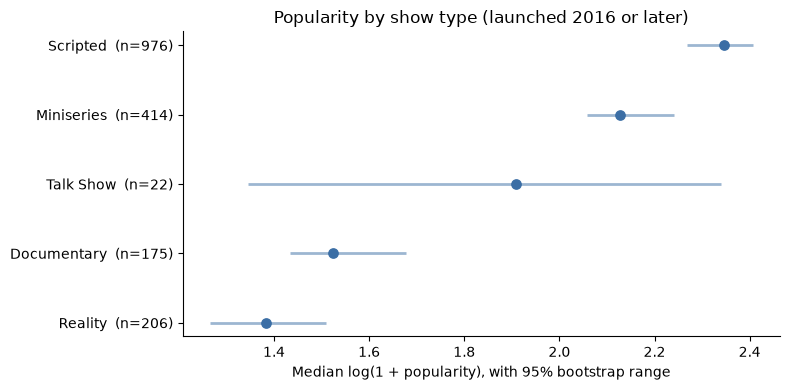

,n,median_log,lo,hi
type,,,,
Scripted,976,2.35,2.27,2.41
Miniseries,414,2.13,2.06,2.24
Talk Show,22,1.91,1.34,2.34
Documentary,175,1.52,1.43,1.68
Reality,206,1.38,1.27,1.51


In [12]:
recent = launched[launched.launch_year >= 2016].copy()

rng = np.random.default_rng(0)

def boot_ci(s, k=1000):
    s = s.to_numpy()
    meds = [np.median(rng.choice(s, len(s))) for _ in range(k)]
    return pd.Series({"lo": np.percentile(meds, 2.5), "hi": np.percentile(meds, 97.5)})

g = recent.groupby("type")
by_type_recent = g.agg(n=("id", "size"), median_log=("log_pop", "median"))
by_type_recent = by_type_recent.join(g.log_pop.apply(boot_ci).unstack())
by_type_recent = by_type_recent.sort_values("median_log")   # lowest first, so the top row is highest

y = np.arange(len(by_type_recent))
fig, ax = plt.subplots(figsize=(8, 4))

ax.hlines(y, by_type_recent.lo, by_type_recent.hi, color="#3b6ea5", lw=2, alpha=0.5)
ax.scatter(by_type_recent.median_log, y, color="#3b6ea5", s=45, zorder=3)

ax.set_yticks(y)
ax.set_yticklabels([f"{t}  (n={n})" for t, n in zip(by_type_recent.index, by_type_recent.n)])
ax.set_xlabel("Median log(1 + popularity), with 95% bootstrap range")
ax.set_title("Popularity by show type (launched 2016 or later)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

by_type_recent.sort_values("median_log", ascending=False).round(2)


**Finding:**
- Two tiers: Scripted (2.35) and Miniseries (2.13) above Documentary (1.52) and Reality (1.38). The ranges do not overlap. Talk Show has 22 shows and a wide range, so no conclusion.
- The order is the same with all launch years included, so launch year does not explain it.
- **Caveat:** type may stand in for budget or marketing, which we do not have. Only launch year was checked.


## Genre

- A show can have several genres, so it counts in each one. Genres with 30 or more shows, shows from 2016 on.
- The 25th to 75th range is the spread of shows, not uncertainty.
- Second table: Scripted shows only, to see if a genre gap survives once type is held fixed.


In [13]:
genre = recent.explode("genres_list").dropna(subset=["genres_list"])

by_genre = genre.groupby("genres_list").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_genre = by_genre[by_genre.n >= 30].sort_values("median_log", ascending=False)
by_genre.round(2)


,n,median_log,q25,q75
genres_list,,,,
Sci-Fi & Fantasy,215,2.70,2.28,3.26
Action & Adventure,199,2.65,2.09,3.35
Mystery,184,2.60,2.07,3.25
Drama,687,2.48,1.91,3.11
Animation,268,2.44,1.99,3.14
Kids,134,2.31,1.72,3.01
Crime,276,2.24,1.77,2.77
Comedy,415,2.23,1.57,2.97
Family,95,2.20,1.61,3.03


In [14]:
scripted = recent[recent.type == "Scripted"]
genre_s = scripted.explode("genres_list").dropna(subset=["genres_list"])

by_genre_s = genre_s.groupby("genres_list").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_genre_s = by_genre_s[by_genre_s.n >= 30].sort_values("median_log", ascending=False)
by_genre_s.round(2)


,n,median_log,q25,q75
genres_list,,,,
Sci-Fi & Fantasy,182,2.74,2.30,3.32
Action & Adventure,168,2.69,2.14,3.40
Mystery,120,2.62,2.04,3.36
Drama,496,2.55,1.91,3.22
Crime,128,2.53,1.98,3.08
Animation,243,2.44,1.97,3.15
Kids,130,2.33,1.75,3.06
Comedy,328,2.32,1.66,3.03
Family,79,2.31,1.82,3.13


**Finding:**
- Across all types, Documentary (1.70) and Reality (1.37) are lowest, and Sci-Fi & Fantasy, Action & Adventure and Mystery are highest. This mostly repeats type: the Reality genre is 80% Reality type.
- Within Scripted the spread shrinks (Sci-Fi & Fantasy 2.74 down to Family 2.31) with heavy overlap. Genre adds little once type is fixed.
- Small lean toward Sci-Fi & Fantasy, Action & Adventure and Mystery, not tested with bootstrap ranges.


## Size and attention (Spearman)

- Spearman uses ranks, so skew and outliers do not matter. Shows from 2016 on, against `log_pop`.
- `vote_count` is an attention signal, like popularity, so it is a sanity check, not a driver.


In [15]:
num_cols = ["number_of_seasons", "number_of_episodes", "episode_run_time", "vote_count"]
corr = recent[num_cols + ["log_pop"]].corr(method="spearman")["log_pop"].drop("log_pop")
corr.round(2)


number_of_seasons     0.35
number_of_episodes    0.38
episode_run_time      0.05
vote_count            0.70
Name: log_pop, dtype: float64

**Finding:**
- `vote_count` 0.70, `number_of_episodes` 0.38, `number_of_seasons` 0.35, `episode_run_time` 0.05 (29% missing). Scripted only: seasons and episodes 0.43.
- Longer-running shows are more popular, probably because shows that do well get renewed (**assumed**). Known only after launch, so not pre-launch features.
- Run length could help rank shows already out there, not predict a new launch. How acquisitions are decided is **assumed**, not known.


## Country and language

- Both are known before launch. Shows from 2016 on, groups with 30 or more shows (a judgement call).
- Country (`origin_country_list`) is multi-label, so a show counts in each of its countries. Language (`original_language`) has one value per show.
- The 25th to 75th range is the spread of shows, not uncertainty.


In [16]:
# country (multi-label)
country = recent.explode("origin_country_list").dropna(subset=["origin_country_list"])
by_country = country.groupby("origin_country_list").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_country = by_country[by_country.n >= 30].sort_values("median_log", ascending=False)
print(by_country.round(2))

# original language (one value per show)
by_lang = recent.groupby("original_language").agg(
    n=("id", "size"),
    median_log=("log_pop", "median"),
    q25=("log_pop", lambda s: s.quantile(.25)),
    q75=("log_pop", lambda s: s.quantile(.75)),
)
by_lang = by_lang[by_lang.n >= 30].sort_values("median_log", ascending=False)
by_lang.round(2)


                       n  median_log   q25   q75
origin_country_list                             
KR                    85        2.75  2.05  3.40
GB                   104        2.42  1.71  2.87
JP                   104        2.30  1.69  2.92
ES                    74        2.26  1.72  2.64
US                   730        2.22  1.58  2.91
IT                    36        2.16  1.41  2.54
MX                    59        2.09  1.61  2.87
FR                    45        2.06  1.60  2.39
DE                    38        2.05  1.52  2.63
BR                    55        1.55  1.12  2.17
IN                    73        1.52  1.15  1.99
TH                    37        1.40  1.12  1.98


,n,median_log,q25,q75
original_language,,,,
ko,84,2.78,2.03,3.41
ja,104,2.30,1.69,2.92
de,35,2.18,1.55,2.65
it,34,2.18,1.52,2.58
en,974,2.12,1.50,2.82
es,181,2.12,1.52,2.71
zh,38,2.05,1.52,2.57
fr,50,1.95,1.37,2.36
hi,54,1.61,1.18,2.15


### Is Korean really higher? A bootstrap test

- Language only (one value per show, so no show is counted twice).
- For each language the 95% bootstrap range of the median. For Korean against each other language, the range of the difference in medians.
- If that difference range excludes 0, the two are separated (`separated_from_ko` True).


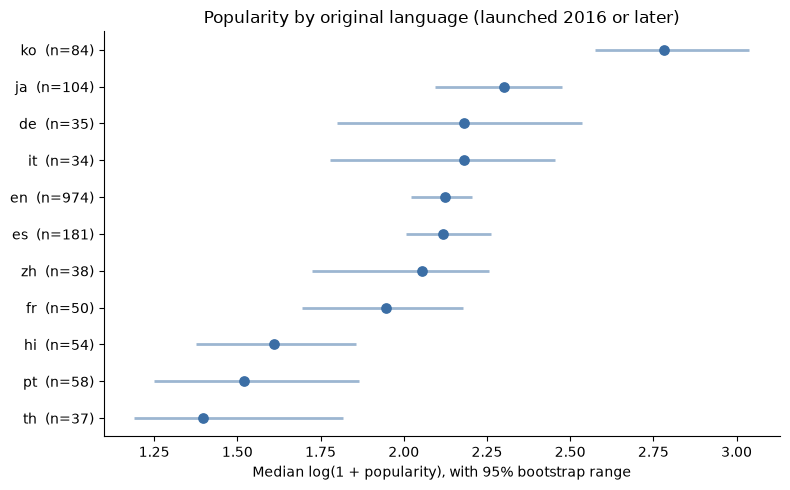

,n,median_log,lo,hi,ko_minus_this,diff_lo,diff_hi,separated_from_ko
language,,,,,,,,
th,37,1.40,1.19,1.82,1.33,0.88,1.68,True
pt,58,1.52,1.25,1.87,1.26,0.81,1.66,True
hi,54,1.61,1.37,1.86,1.17,0.83,1.53,True
fr,50,1.95,1.69,2.18,0.85,0.52,1.17,True
zh,38,2.05,1.72,2.26,0.79,0.41,1.18,True
es,181,2.12,2.01,2.26,0.65,0.37,0.92,True
en,974,2.12,2.02,2.20,0.67,0.42,0.94,True
it,34,2.18,1.78,2.45,0.65,0.22,1.09,True
de,35,2.18,1.80,2.54,0.61,0.21,1.08,True


In [17]:
def boot_median(s, k=1000):
    s = s.to_numpy()
    return np.array([np.median(rng.choice(s, len(s))) for _ in range(k)])

def lang_test(df, ref="ko", min_n=30):
    rng_local = np.random.default_rng(0)
    groups = {l: g.log_pop for l, g in df.groupby("original_language") if len(g) >= min_n}
    boots = {l: np.array([np.median(rng_local.choice(s.to_numpy(), len(s))) for _ in range(1000)])
             for l, s in groups.items()}
    rows = []
    for l, s in groups.items():
        diff = boots[ref] - boots[l] if l != ref else np.zeros(1000)
        rows.append({"language": l, "n": len(s), "median_log": s.median(),
                     "lo": np.percentile(boots[l], 2.5), "hi": np.percentile(boots[l], 97.5),
                     f"{ref}_minus_this": diff.mean(),
                     "diff_lo": np.percentile(diff, 2.5), "diff_hi": np.percentile(diff, 97.5)})
    out = pd.DataFrame(rows).set_index("language").sort_values("median_log")
    out["separated_from_ko"] = (out.diff_lo > 0) | (out.diff_hi < 0)
    return out

res = lang_test(recent)

y = np.arange(len(res))
fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(y, res.lo, res.hi, color="#3b6ea5", lw=2, alpha=0.5)
ax.scatter(res.median_log, y, color="#3b6ea5", s=45, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([f"{l}  (n={n})" for l, n in zip(res.index, res.n)])
ax.set_xlabel("Median log(1 + popularity), with 95% bootstrap range")
ax.set_title("Popularity by original language (launched 2016 or later)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

res.round(2)


In [ ]:
# same test on Scripted shows only, to check type is not behind it
lang_test(recent[recent.type == "Scripted"]).round(2)


**Finding:**
- Korean is the most popular language (median 2.78, range 2.57 to 3.04, 84 shows) and is separated from every other language, in all shows and in Scripted only (2.91, 48 shows). Korea is also top by country.
- English is fifth (2.12), almost tied with Spanish, Italian and German, so the middle order is noise. Its range is narrow (974 shows) because the median is well pinned down, not because English shows are alike.
- Thai (1.40), Portuguese (1.52) and Hindi (1.61) are lowest, in both runs.
- Country and language say the same thing, so one is enough as a feature. Both are known before launch.
- **Caveats:** 10 comparisons with no correction. **Assumed:** TMDB popularity reflects its own audience mix. Association only, and only noise from sample size is tested.


## Creators and production companies

- Both are known before launch and are multi-label (a show counts under each name). Shows from 2016 on.
- First check how often each name repeats, because a name seen once cannot be compared.
- Cut-offs (10 shows for companies, 4 for creators) are judgement calls. The 25th to 75th range is the spread of shows, not uncertainty.


In [ ]:
def group_table(df, col, explode=False, min_n=30):
    d = df.explode(col).dropna(subset=[col]) if explode else df
    t = d.groupby(col).agg(
        n=("id", "size"),
        median_log=("log_pop", "median"),
        q25=("log_pop", lambda s: s.quantile(.25)),
        q75=("log_pop", lambda s: s.quantile(.75)),
    )
    return t[t.n >= min_n].sort_values("median_log", ascending=False).round(2)

# 1. coverage: how often does each name repeat?
for col in ["created_by_list", "production_companies_list"]:
    ex = recent.explode(col).dropna(subset=[col])
    counts = ex[col].value_counts()
    print(col, "| shows with a value:", recent[col].notna().sum(), "of", len(recent),
          "| distinct names:", len(counts),
          "| in 5+ shows:", (counts >= 5).sum(), "| in 10+:", (counts >= 10).sum())

# 2. names that repeat
print(group_table(recent, "production_companies_list", explode=True, min_n=10))
print(group_table(recent, "created_by_list", explode=True, min_n=4))

# 3. is a missing value itself a signal?
for col in ["created_by_list", "production_companies_list"]:
    print(col)
    print(recent.groupby(recent[col].notna()).log_pop.agg(["size", "median"]).round(2))


**Finding:**
- Creators are too sparse to compare: 983 shows have one, 1,343 distinct names, only 5 names in 5 or more shows. Companies: 1,283 shows, 1,383 names, 48 in 5 or more, 9 in 10 or more.
- Top companies: Studio Dragon 3.43 (12 shows), Warner Bros. Television 3.35 (14), DreamWorks Animation Television 3.30 (16), Netflix 2.88 (24). Lowest: Boardwalk Pictures 1.59 (12). Small groups, no bootstrap range. Studio Dragon is Korean, so it probably repeats the language result.
- Missing is a strong signal: median 2.40 with a creator vs 1.68 without, 2.29 with a company vs 1.52 without. **Assumed:** better-known shows have fuller pages. We cannot tell if the page was filled in before launch or after the show got popular, so treat it with caution as a pre-launch feature.
- A name scan (all 2,031 shows) found few real variants: some company parents (DreamWorks, Gaumont, Entertainment One) and one creator pair. Most names are distinct, so the sparsity is real. The scan only catches similar-looking names. An alias or parent map is a next-time item.
- **Takeaway:** names are too sparse to be features. A has-a-value flag is stronger, but it is a data-completeness signal, not a cause.
